In [1]:

import numpy as np
import pandas as pd
import os
import rioxarray as rxr
from osgeo import gdal
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline, make_pipeline
import geopandas as gpd
import rasterio
from shapely.geometry import box
from shapely.geometry import Point
from rasterio.sample import sample_gen
import xgboost as xgb
from scipy.stats import gaussian_kde
from scipy.stats import pearsonr
from sklearn.metrics import r2_score

from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from skopt import BayesSearchCV
from skopt.space import Integer, Real

c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\cupy\_environment.py:215: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


In [3]:
def save_img(output_filename, reference_filename, array):
    
    reference = gdal.Open(reference_filename)
    
    # 获取地理变换参数和坐标系
    geo_transform = reference.GetGeoTransform()
    projection = reference.GetProjection()

    # 获取矩阵尺寸
    rows, cols = array.shape

    # 创建新的 TIFF 数据集
    driver = gdal.GetDriverByName('GTiff')
    out_data = driver.Create(output_filename, cols, rows, 1, gdal.GDT_Float32)

    # 设置地理变换和坐标系
    out_data.SetGeoTransform(geo_transform)
    out_data.SetProjection(projection)
    

    # 写入数据
    out_data.GetRasterBand(1).WriteArray(array)

    # 保存并关闭文件
    out_data.FlushCache()
    out_data = None
    
def load_refer_ICESat_point(FB_raster, icesat_csv_path, output_point, output_raw_point):
    
    df = pd.read_csv(icesat_csv_path)
    lon, lat = 'mean_lon', 'mean_lat'
    LULC_path = "E:/Downloads/tes/UK_LULC.tif"
    geometry = [Point(xy) for xy in zip(df[lon], df[lat])]
    gdf = gpd.GeoDataFrame(df, geometry=geometry)
    gdf.set_crs(epsg=4326, inplace=True)
    points = gdf
    
    with rasterio.open(FB_raster) as src:
        
        if points.crs != src.crs:
            points = points.to_crs(src.crs)
        coords = [(point.x, point.y) for point in points.geometry]
        values = list(src.sample(coords))
        
        band_count = src.count
        for band in range(band_count):
            points[f"b{band+1}_FB6"] = [v[band] for v in values]
            
    with rasterio.open(LULC_path) as src:

        if points.crs != src.crs:
            points = points.to_crs(src.crs)
        coords = [(point.x, point.y) for point in points.geometry]
        values = list(src.sample(coords))

        band_count = src.count
        points['LULC'] = [v[0] for v in values] 
     
    icesat_mask = (points['OH'] < 5) & (points['b7_FB6'] > 0)# & ((points['LULC'] == 200) | (points['LULC'] == 80))
    data = points[icesat_mask]
    
    points.to_file(output_raw_point)
    data.to_file(output_point)
    
    return data

def optimize_random_forest(x_train, y_train,  n_iter=30, cv=3):

    # if feature_columns is None:
    #     raise ValueError("feature_columns must be provided.")

    classifier = RandomForestRegressor(random_state=42)

    search_space = {
        'n_estimators': Integer(50, 500),
        'max_depth': Integer(3, 20),
        'min_samples_split': Integer(2, 20),
        'min_samples_leaf': Integer(1, 20),
        'max_features': Real(0.1, 1.0)
    }

    opt = BayesSearchCV(
        estimator=classifier,
        search_spaces=search_space,
        n_iter=n_iter,
        cv=cv,
        scoring='neg_mean_squared_error',
        random_state=42,
        n_jobs=-1
    )

    opt.fit(x_train, y_train)

    best_params = opt.best_params_
    print('Best hyperparameters:', best_params)
    print('Best score (negative MSE):', opt.best_score_)

    # 使用最优参数重新训练模型
    final_model = RandomForestRegressor(**best_params, random_state=42)
    # final_model.fit(x_train, y_train)

    return best_params, final_model


In [ ]:
region = 'Region4'
location = 'Ribble'
year = 2022
method = 'MpPoly'
band = 4
target_band_list, target_id_list = ['b1_FB6','b2_FB6','b3_FB6','b4_FB6'], [0, 1, 2, 3]
target_band, target_id = target_band_list[:band], target_id_list[:band]


LULC_path = "E:/Downloads/tes/UK_LULC.tif"
LULC = rxr.open_rasterio(LULC_path, masked=True).squeeze()

FB_raster_path = f"G:\ICESat-2\Discussion5_1_new\{location}1_{year}_FB6_new9.tif"
ICESAT_csv_path = f'G:\ICESat-2\{region}\{region}_{location}\A_{location}_30m_{year}_new10.csv'
output_path = f'G:\ICESat-2\Discussion5_1_new\{location}_{year}_{band}_{method}_FB6_new9.tif'
output_raw_point = f'G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_raw_new10.shp'
output_point = f'G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10.shp'
data = load_refer_ICESat_point(FB_raster_path, ICESAT_csv_path, output_point, output_raw_point)
y_train = data['OH'].values
x_train = data[target_band].values
print(x_train.shape)
if method == 'RF':
    
    best_params, classifier = optimize_random_forest(x_train, y_train)
    classifier.fit(x_train, y_train)

elif method == 'Linear':
    classifier = np.polyfit(x_train[:, 0], y_train, deg=1)
elif method == 'Poly':
    classifier = np.polyfit(x_train[:, 0], y_train, deg=2)
elif method == 'MpLinear':
    classifier = LinearRegression()
    classifier.fit(x_train, y_train)
elif method == 'MpPoly':
    degree = 2 # 设置多项式的阶数
    classifier = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    classifier.fit(x_train, y_train)
else:
    print('error classifier input')
    
if not os.path.exists(FB_raster_path):
    print(FB_raster_path, 'is not exist!')

raster = rxr.open_rasterio(FB_raster_path).values
raster = np.nan_to_num(raster, nan=0)
selected_raster = raster[target_id, :, :]

if len(selected_raster.shape) != 3:
    row, col = selected_raster.shape
    selected_raster = selected_raster.reshape(1, row, col)
else: 
    bands, row, col = selected_raster.shape
    
k = 0
result = np.array([[]])
for i in range(row):
                
    x_train = np.transpose(selected_raster[:, i, :])
    if method == 'RF':
        y_pred = classifier.predict(x_train)
    elif method == 'Linear':
        y_pred = np.polyval(classifier, x_train)
    elif method == 'MpLinear':
        y_pred = classifier.predict(x_train)
    elif method == 'MpPoly':
        y_pred = classifier.predict(x_train)
    else:
        y_pred = np.polyval(classifier, x_train)
                
    result = np.append(result, y_pred)
                
    if i%(int(row/5)) == 0:
                    
        print(k*20 , '%_ is done')
        k = k+1
        
result = result.reshape(row, col)
print(result.shape, type(result))
tf_mask = raster[6,:,:]
z = rxr.open_rasterio(FB_raster_path, masked=True).squeeze() 
LULC_aligned = LULC.rio.reproject_match(z)
result[(tf_mask == 0)] = 0
save_img(output_path, FB_raster_path, result)
print(f'{location}_{year} is output to {output_path}')

C:\Users\minyu\AppData\Local\Temp\ipykernel_29456\2485913402.py:62: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  points.to_file(output_raw_point)
c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normalized/laundered field name: 'Unnamed: 0' to 'Unnamed_ 0'
  ogr_write(
c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normalized/laundered field name: 'mean_height' to 'mean_heigh'
  ogr_write(
C:\Users\minyu\AppData\Local\Temp\ipykernel_29456\2485913402.py:63: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  data.to_file(output_point)
c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normalized/laundered field name: 'Unnamed: 0' to 'Unnamed_ 0'
  ogr_write(
c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normal

(1624, 4)
0 %_ is done
20 %_ is done
40 %_ is done
60 %_ is done
80 %_ is done
100 %_ is done
(1649, 1064) <class 'numpy.ndarray'>
Ribble_2022 is output to G:\ICESat-2\Discussion5_1_new\Ribble_2022_4_MpPoly_FB6_new9.tif


In [11]:
#------------------validation-----------------------
path = r'G:\ICESat-2\Region1_map\Thames1_map\A2022\Thames1_2022_sample_points_final.shp'
# path = r'G:\ICESat-2\Region4_map\Ribble1_map\A2019\Ribble1_2019_sample_points_final.shp'
# path = r'G:\ICESat-2\Region2_map\wash_bay_map\A2022\wash_bay_2022_sample_points_final.shp'
path = r'G:\ICESat-2\Region4_map\Morecambe_map\A2023\Morecambe_2023_sample_points_final.shp'
z = gpd.read_file(path)

output = z[['Refer_dem', 'geometry']]
output_path = r'G:\ICESat-2\Discussion5_1_new\Validation_point_Morecambe.shp'
output.to_file(output_path)

In [12]:

points_path = output_path
out_points_path = output_path
points = gpd.read_file(points_path)

for method in ['RF', 'Linear', 'Poly']:
    
    if method == 'RF':
        raster_path = f'G:\ICESat-2\Discussion5_1_new\Morecambe_2023_4_{method}_FB6_new7.tif'
    else:
        raster_path = f'G:\ICESat-2\Discussion5_1_new\Morecambe_2023_1_{method}_FB6_new7.tif'
    with rasterio.open(raster_path) as src:
                    
        raster_crs = src.crs
        if points.crs != raster_crs:
            points = points.to_crs(raster_crs)
                    
        coords = [(geom.x, geom.y) for geom in points.geometry]
        values = list(src.sample(coords))
                    
        band_values = [val[0] for val in values]
                    
        points[f'{method}_dem'] = band_values
        
points.to_file(out_points_path)
points.columns

Index(['Refer_dem', 'geometry', 'RF_dem', 'Linear_dem', 'Poly_dem'], dtype='object')

R² = 0.742, MAE = 0.735, MSB = 0.370, RMSE = 0.919, N = 10327


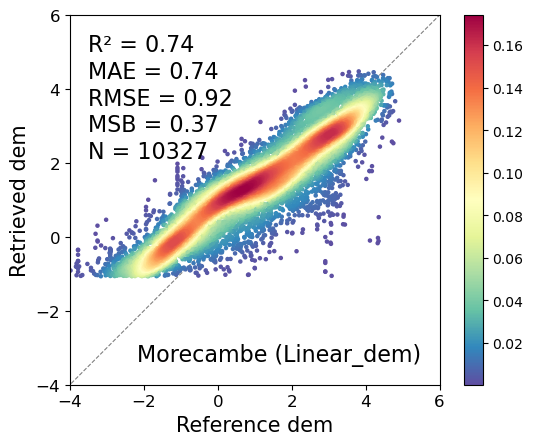

R² = 0.776, MAE = 0.605, MSB = 0.341, RMSE = 0.856, N = 10327


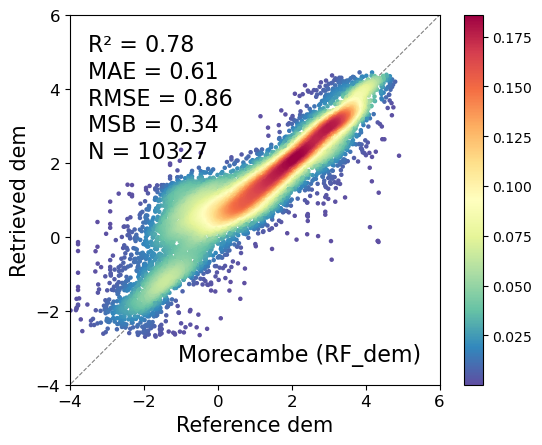

R² = 0.743, MAE = 0.733, MSB = 0.369, RMSE = 0.916, N = 10327


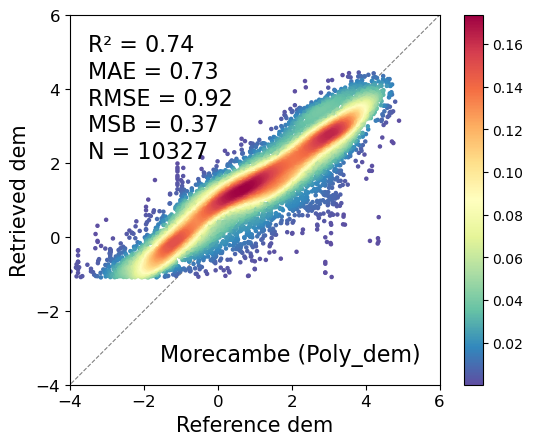

In [ ]:
import matplotlib.pyplot as plt
location2 = 'Morecambe'
target_name_list = ['Linear_dem', 'RF_dem', 'Poly_dem']
for target_name in target_name_list:
    
    z = points[['Refer_dem', target_name]]
    mask = (z[target_name] != 0) | (z['Refer_dem'] !=6) | (z['Refer_dem'] != -999)
    z = z[mask]
    z = z[z!=-999]
    z = z[z!=6]
    z = z[z!=0]
    z = z.dropna()
    x = np.array(z['Refer_dem']) #y_true
    y = np.array(z[target_name]) # y_pred
    xy_lim_range = [-3, 5]
        # R, _ = pearsonr(y, x)
    R2 = r2_score(x, y) #r2_score(y_true, y_pred)
    MAE = np.mean(np.abs(y-x))
    MSB = np.mean((y-x))
    RMSE = np.sqrt(np.mean((y-x)**2))
    num = int(len(x))

    print(f"R² = {R2:.3f}, MAE = {MAE:.3f}, MSB = {MSB:.3f}, RMSE = {RMSE:.3f}, N = {num}")
        
    xy = np.vstack([x,y])  #  将两个维度的数据叠加
    z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

        # Sort the points by density, so that the densest points are plotted last
    idx = z.argsort()
    x_sorted, y_sorted, z_sorted = x[idx], y[idx], z[idx]

    fig, ax = plt.subplots()
    textstr = f"R² = {R2:.2f}\nMAE = {MAE:.2f}\nRMSE = {RMSE:.2f} \nMSB = {MSB:.2f}\nN = {num}"
    name = f'{location2} ({target_name})'
    ax.text(0.05, 0.95, textstr, transform = ax.transAxes, fontsize = 16, verticalalignment = 'top')
    ax.text(0.95, 0.05, name, transform=ax.transAxes, fontsize=16, verticalalignment='bottom', horizontalalignment='right')

    ax.set_xlabel('Reference dem', fontsize = 15)
    ax.set_ylabel('Retrieved dem', fontsize = 15)
    ax.plot([-6, 6], [-6, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)

    sc = plt.scatter(x_sorted, y_sorted, c=z_sorted, s=5, cmap='Spectral_r', zorder=2)
    cbar = plt.colorbar(sc)

        # plt.scatter(x, y,c=z, s=2,cmap='Spectral_r') # c表示标记的颜色
        # plt.colorbar()

    ax.set_xlim(-4, 6.1)
    ax.set_ylim(-4, 6)

    # 设置一致的刻度间隔（例如每 1 单位一个刻度）
    tick_interval = 2
    ticks = np.arange(-4, 4.1 + tick_interval, tick_interval)
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)

    # 设置等比例显示
    ax.set_aspect('equal')

    ax.tick_params(axis='both', labelsize=12)
    output_path = f'G:\ICESat-2\Discussion5_1_new\plot/{location2}_{target_name}.png'
    plt.savefig(output_path, dpi=300, bbox_inches='tight')  # 保存图像
    plt.show()
    plt.close()